In [16]:
from qiskit_aer import AerSimulator
from qiskit_aer.noise import NoiseModel, depolarizing_error
from qiskit.circuit import QuantumCircuit
from qiskit import transpile

qc = QuantumCircuit(1, 1)
qc.x(0)
qc.measure(0, 0)
    
# Build noise model
noise_model = NoiseModel()
error = depolarizing_error(0.75, 1)
noise_model.add_all_qubit_quantum_error(
    error, ['u1', 'u2', 'u3', 'u', 'p', 'sx', 'x', 'rx', 'ry', 'rz']
)

# Noiseless
sim_ideal = AerSimulator()
result_ideal = sim_ideal.run(transpile(qc, sim_ideal), shots=1024).result()
print("Noiseless     :", result_ideal.get_counts())

# Noisy
sim_noisy = AerSimulator(noise_model=noise_model)
result_noisy = sim_noisy.run(transpile(qc, sim_noisy), shots=1024).result()
print("Noisy p=0.75  :", result_noisy.get_counts())

sim_check = AerSimulator()
qc_t = transpile(qc, sim_check)
print("Basis gates used:", qc_t.count_ops())

import numpy as np
import matplotlib.pyplot as plt
import matplotlib.patches as mpatches
import json

from qiskit.circuit import QuantumCircuit
from qiskit import transpile
from qiskit_aer import AerSimulator
from qiskit_aer.noise import NoiseModel, depolarizing_error
from qiskit_aer.primitives import Sampler as AerSampler
from qiskit_algorithms import IterativeAmplitudeEstimation, EstimationProblem

print("All imports OK ✅")

p_true = 0.4  ########################################################################################################

class BernoulliA(QuantumCircuit):
    def __init__(self, probability):
        super().__init__(1)
        theta_p = 2 * np.arcsin(np.sqrt(probability))
        self.ry(theta_p, 0)

class BernoulliQ(QuantumCircuit):
    def __init__(self, probability):
        super().__init__(1)
        self._theta_p = 2 * np.arcsin(np.sqrt(probability))
        self.ry(2 * self._theta_p, 0)

    def power(self, k):
        q_k = QuantumCircuit(1)
        # ---------------------------------------------------------
        # REWRITTEN: Apply base rotation k times separated by barriers
        # to ensure the noise model acts k times.
        # ---------------------------------------------------------
        for _ in range(k):
            q_k.ry(2 * self._theta_p, 0)
            q_k.barrier() 
        return q_k

problem = EstimationProblem(
    state_preparation=BernoulliA(p_true),
    grover_operator=BernoulliQ(p_true),
    objective_qubits=[0],
)
print("Problem defined ✅")
    

# ══════════════════════════════════════════════════════════════════════════════
# NOISE MODEL BUILDER
# ══════════════════════════════════════════════════════════════════════════════
# All standard single-qubit basis/native gates Qiskit might emit
SINGLE_QUBIT_GATES = [
    'id', 'x', 'y', 'z', 'h', 's', 'sdg', 't', 'tdg',
    'sx', 'sxdg', 'rx', 'ry', 'rz',
    'u', 'u1', 'u2', 'u3', 'p'
]

# Physical ceiling for 1-qubit depolarizing_error:
#   E(rho) = (1-λ)ρ + (λ/4)(ρ + XρX + YρY + ZρZ)
#   => c_I = 1 - 3λ/4, c_X = c_Y = c_Z = λ/4
#   CP requires all c >= 0  =>  λ ∈ [0, 4/3]
#   λ = 1 is full depolarization (output = I/2); λ ∈ (1, 4/3] is
#   "over-rotation" with no interpretable "more noise" meaning here.
# For a noise-frontier sweep, the meaningful physical range is λ ∈ [0, 1].
MAX_DEPOL_LAMBDA = 1.0          # λ ≤ 1: physically meaningful range

def build_noisy_sampler(lambda_depol, n_shots):
    if lambda_depol > 0.0:
        lam = min(lambda_depol, MAX_DEPOL_LAMBDA)
        error_1q = depolarizing_error(lam, 1)

        noise_model = NoiseModel()
        noise_model.add_all_qubit_quantum_error(error_1q, SINGLE_QUBIT_GATES)

        sampler = AerSampler(
            backend_options={"noise_model": noise_model},
            run_options={"shots": n_shots}
        )
    else:
        sampler = AerSampler(run_options={"shots": n_shots})
    return sampler

Noiseless     : {'1': 1024}
Noisy p=0.75  : {'0': 379, '1': 645}
Basis gates used: OrderedDict({'x': 1, 'measure': 1})
All imports OK ✅
Problem defined ✅


In [17]:
# ══════════════════════════════════════════════════════════════════════════════
# CELL 1 — Parameters + Helper Functions  (fixed)
# ══════════════════════════════════════════════════════════════════════════════

import numpy as np
from joblib import Parallel, delayed


R         = 1000
ALPHA     = 0.05
N_JOBS    = 18

TARGET         = 0.50
CONV_BAND = 0.02
LOCAL_HALF_WIDTH = 0.05   # warm-start lambda window: [p*_prev - 0.05, p*_prev + 0.05]
PRECISION      = 0.0001

epsilon_values = np.arange(0.0001, np.pi/8, 0.001).tolist()


def success_rate(k, n):
    return k / n


# ── Ceiling N_max ──────────────────────────────────────────────────────────────
# Rounds down to prevent from overshooting the theoretical limit
def N_max_Chernoff(epsilon, alpha):
    raw = (32 / (1 - 2 * np.sin(np.pi / 14)) ** 2) \
          * np.log((2 / alpha) * np.log2(np.pi / (4 * epsilon)))
    return int(np.floor(raw))

def N_max_CP(epsilon, alpha):
    raw = 69 * np.log((2 / alpha) * np.log2(np.pi / (4 * epsilon)))
    return int(np.floor(raw))

In [18]:
# ══════════════════════════════════════════════════════════════════════════════
# CELL 2 — Single run + Probe
# ══════════════════════════════════════════════════════════════════════════════

def single_run(p_noise, eps, N_SHOTS):
    """One IQAE run at a fixed shot budget. Returns 1 (success) or 0 (failure)."""
    try:
        sampler = build_noisy_sampler(p_noise, N_SHOTS)
        iae     = IterativeAmplitudeEstimation(
            epsilon_target = eps,
            alpha          = ALPHA,
            sampler        = sampler,
            confint_method    = "beta" #chernoff" "beta"###################################################
        )
        result  = iae.estimate(problem)
        return 1 if abs(result.estimation_processed - p_true) <= eps else 0
    except Exception as e:
        print(f"[WARN] single_run failed: {type(e).__name__}: {e}")
        return 0


def probe(eps, p):
    """
    Run R independent IQAE runs at (eps, p) in parallel, at the ceiling
    shot budget N_max(eps, ALPHA).
    Returns (s_hat, lower_CI, upper_CI, half_width, N_SHOTS).
    """
    N_SHOTS = N_max_CP(eps, ALPHA)   ##########################################

    outcomes           = Parallel(n_jobs=N_JOBS)(
        delayed(single_run)(p, eps, N_SHOTS) for _ in range(R)
    )
    k                  = sum(outcomes)
    s_hat = success_rate(k, R)
    return s_hat, N_SHOTS

In [19]:
# ══════════════════════════════════════════════════════════════════════════════
# CELL 3 — Bisection
# ══════════════════════════════════════════════════════════════════════════════

def find_boundary(eps, p_low, p_high):
    """
    Bisect over p to find p* where success rate ≈ 50% ± CONV_BAND.
    Matches the pseudocode agreed in transcript exactly.
    """
    history = []

    while (p_high - p_low) > PRECISION:

        p_mid                      = (p_low + p_high) / 2.0
        s_hat, n_shots = probe(eps, p_mid)

        history.append({
            "p_try"       : p_mid,
            "s_hat"       : s_hat,
            "n_shots"     : n_shots,
        })

        print(f"    ε={eps:.4f} | p={p_mid:.4f} | "
              f"s={s_hat:.3f} | "
              f"N_shots={n_shots} | "
              f"window=[{p_low:.4f}, {p_high:.4f}]")

        if s_hat > TARGET + CONV_BAND:
            # ✅ Success rate too high → boundary is above p_mid → raise floor
            p_low  = p_mid

        elif s_hat < TARGET - CONV_BAND:
            # ✅ Success rate too low → boundary is below p_mid → lower ceiling
            p_high = p_mid

        else:
            # ✅ In band [0.45, 0.55] → converged
            print(f"    ✅ Converged at p={p_mid:.4f}")
            return {
                "epsilon"     : eps,
                "p_star"      : p_mid,
                "s_hat"       : s_hat,
                "n_shots"     : n_shots,
                "converged"   : True,
                "cliff"       : False,
                "history"     : history,
                "final_p_low" : p_low,
                "final_p_high": p_high,
                "uncertainty": (p_high - p_low) / 2.0,
            }

    p_best                     = (p_low + p_high) / 2.0
    s_hat, n_shots = probe(eps, p_best)

    print(f"    ⚠️  Precision limit at p={p_best:.4f} | s={s_hat:.3f}")
    return {
        "epsilon"     : eps,
        "p_star"      : p_best,
        "s_hat"       : s_hat,
        "n_shots"     : n_shots,
        "converged"   : False,
        "cliff"       : False,
        "history"     : history,
        "final_p_low" : p_low,
        "final_p_high": p_high,
        "uncertainty": (p_high - p_low) / 2.0,
    }

In [20]:
# ══════════════════════════════════════════════════════════════════════════════
# CELL 4 — Outer sweep (added: early termination if p* saturates at 1.0)
# ══════════════════════════════════════════════════════════════════════════════

def sweep_frontier(epsilon_list, local_half_width=LOCAL_HALF_WIDTH):

    results     = []
    p_star_prev = None

    for eps in epsilon_list:

        print(f"\n{'─'*60}")
        print(f"  ε = {eps:.4f}")
        print(f"{'─'*60}")

        # ── CASE 1: First epsilon ─────────────────────────────────────────────
        if p_star_prev is None:
            p_low  = 0.0
            p_high = 1.0
            cliff  = False
            print("  First ε — bisecting full range [0.0, 1.0]")

        # ── CASE 2: Subsequent epsilons ───────────────────────────────────────
        else:

            print(f"  Probing at previous p* = {p_star_prev:.4f} ...")
            s_probe, n_shots_probe = probe(eps, p_star_prev)
            print(f"  Probe: s={s_probe:.3f} "
                  f"| N_shots={n_shots_probe}")

            if abs(s_probe - TARGET) <= CONV_BAND:
                p_low  = max(0.0, p_star_prev - local_half_width)
                p_high = min(1.0, p_star_prev + local_half_width)
                cliff  = False
                print(f"  Near boundary — local refinement in "
                      f"[{p_low:.4f}, {p_high:.4f}]")

            elif s_probe > TARGET + CONV_BAND:
                p_low  = p_star_prev
                p_high = 1.0
                cliff  = True
                print(f"  ⚠️  Cliff detected (s={s_probe:.3f}) — "
                      f"searching [{p_low:.4f}, {p_high:.4f}]")

            else:
                p_low  = 0.0
                p_high = p_star_prev
                cliff  = False
                print(f"  ⚠️  Boundary dropped (s={s_probe:.3f}) — "
                      f"searching [{p_low:.4f}, {p_high:.4f}]")

        # ── Bisect ────────────────────────────────────────────────────────────
        result          = find_boundary(eps, p_low, p_high)
        result["cliff"] = cliff
        result["search_window_low"]  = p_low
        result["search_window_high"] = p_high
        result["used_local_refinement"] = (
            p_star_prev is not None
            and abs(result["search_window_low"]
                    - max(0.0, p_star_prev - local_half_width)) < 1e-12
            and abs(result["search_window_high"]
                    - min(1.0, p_star_prev + local_half_width)) < 1e-12
            if p_star_prev is not None else False
        )

        results.append(result)
        p_star_prev = result["p_star"]

        status = "✅ converged" if result["converged"] else "⚠️  precision limit"
        print(f"\n  {status} | p* = {result['p_star']:.4f} | "
              f"s = {result['s_hat']:.3f} | N_shots = {result['n_shots']}")


    return results

In [21]:
# ══════════════════════════════════════════════════════════════════════════════
# CELL 5 — Full run
# ══════════════════════════════════════════════════════════════════════════════

frontier_results = sweep_frontier(epsilon_values)

print(f"\n{'═'*60}")
print(f"  ✅ Frontier sweep complete — {len(frontier_results)} points")
print(f"{'═'*60}")

for r in frontier_results:
    cliff_tag = " ⚠️  CLIFF" if r["cliff"] else ""
    conv_tag  = "✅" if r["converged"] else "⚠️ "
    print(f"  {conv_tag} ε={r['epsilon']:.5f} | "
          f"p*={r['p_star']:.4f} ± {r['uncertainty']:.4f} | "
          f"s={r['s_hat']:.3f} | "
          f"N={r['n_shots']}{cliff_tag}")


────────────────────────────────────────────────────────────
  ε = 0.0001
────────────────────────────────────────────────────────────
  First ε — bisecting full range [0.0, 1.0]
    ε=0.0001 | p=0.5000 | s=0.000 | N_shots=431 | window=[0.0000, 1.0000]
    ε=0.0001 | p=0.2500 | s=0.000 | N_shots=431 | window=[0.0000, 0.5000]
    ε=0.0001 | p=0.1250 | s=0.001 | N_shots=431 | window=[0.0000, 0.2500]
    ε=0.0001 | p=0.0625 | s=0.001 | N_shots=431 | window=[0.0000, 0.1250]
    ε=0.0001 | p=0.0312 | s=0.003 | N_shots=431 | window=[0.0000, 0.0625]
    ε=0.0001 | p=0.0156 | s=0.019 | N_shots=431 | window=[0.0000, 0.0312]
    ε=0.0001 | p=0.0078 | s=0.052 | N_shots=431 | window=[0.0000, 0.0156]
    ε=0.0001 | p=0.0039 | s=0.147 | N_shots=431 | window=[0.0000, 0.0078]
    ε=0.0001 | p=0.0020 | s=0.328 | N_shots=431 | window=[0.0000, 0.0039]
    ε=0.0001 | p=0.0010 | s=0.611 | N_shots=431 | window=[0.0000, 0.0020]
    ε=0.0001 | p=0.0015 | s=0.406 | N_shots=431 | window=[0.0010, 0.0020]
    ε=

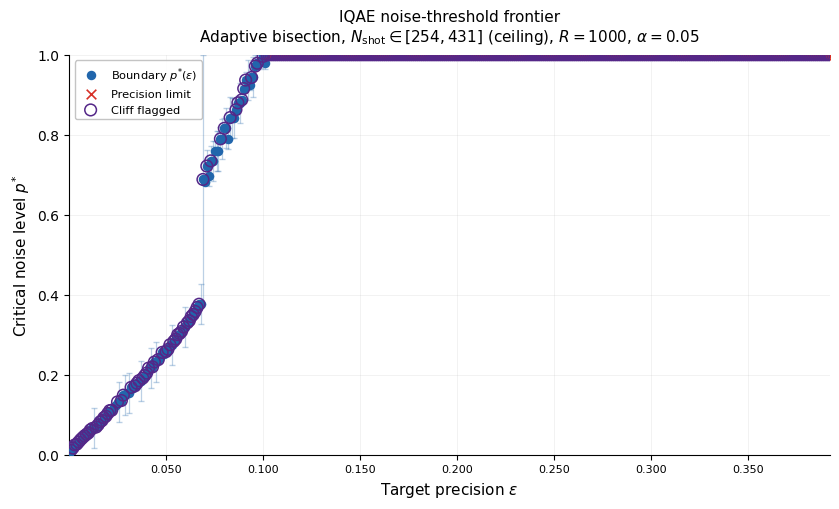

✅ Exported to: c:\Summer-Research-2026\Ceiling analysis\adaptive_searchCP_Nmax, a = 0.4, k-depedent.txt
c:\Summer-Research-2026\Ceiling analysis\adaptive_searchCP_Nmax, a = 0.4, k-depedent.txt


In [22]:
# ══════════════════════════════════════════════════════════════════════════════
# CELL 6+7 — Plot + Export (uncertainty taken directly from result dict)
# ══════════════════════════════════════════════════════════════════════════════

import matplotlib.pyplot as plt
import matplotlib.ticker as ticker
import numpy as np
from datetime import datetime
import os
import math

# ── Build plotting arrays ─────────────────────────────────────────────────────
eps_vals     = [r["epsilon"]   for r in frontier_results]
p_star_vals  = [r["p_star"]    for r in frontier_results]
conv_mask    = [r["converged"] for r in frontier_results]
cliff_mask   = [r.get("cliff", False) for r in frontier_results]
n_shots_vals = [r["n_shots"]   for r in frontier_results if r.get("n_shots") is not None]

# ── Pull uncertainty directly from stored result ──────────────────────────────
# find_boundary() stores: "uncertainty": (p_high - p_low) / 2.0
# Symmetric bar: lower_err = upper_err = uncertainty
uncertainties = [r["uncertainty"] for r in frontier_results]
yerr = np.array([uncertainties, uncertainties])   # shape (2, N)

# ── Figure setup ──────────────────────────────────────────────────────────────
fig, ax = plt.subplots(figsize=(8.5, 5.2))

# ── Error bars on p* ──────────────────────────────────────────────────────────
ax.errorbar(
    eps_vals,
    p_star_vals,
    yerr=yerr,
    fmt='none',
    ecolor='#2166ac',
    alpha=0.30,
    capsize=2.5,
    elinewidth=0.9,
    label='_nolegend_'
)

# ── Converged points ──────────────────────────────────────────────────────────
conv_eps = [e for e, cv in zip(eps_vals, conv_mask) if cv]
conv_p   = [p for p, cv in zip(p_star_vals, conv_mask) if cv]
ax.scatter(
    conv_eps, conv_p,
    color='#2166ac', s=34, zorder=3,
    label=r'Boundary $p^{*}(\varepsilon)$'
)

# ── Not-converged points ──────────────────────────────────────────────────────
nc_eps = [e for e, cv in zip(eps_vals, conv_mask) if not cv]
nc_p   = [p for p, cv in zip(p_star_vals, conv_mask) if not cv]
if nc_eps:
    ax.scatter(
        nc_eps, nc_p,
        color='#d73027', marker='x', s=48,
        linewidths=1.2, zorder=4,
        label='Precision limit'
    )

# ── Cliff-flagged points ──────────────────────────────────────────────────────
cliff_eps = [e for e, cf in zip(eps_vals, cliff_mask) if cf]
cliff_p   = [p for p, cf in zip(p_star_vals, cliff_mask) if cf]
if cliff_eps:
    ax.scatter(
        cliff_eps, cliff_p,
        facecolors='none', edgecolors='#542788',
        s=70, linewidths=1.1, zorder=5,
        label='Cliff flagged'
    )

# ── Axes & styling ────────────────────────────────────────────────────────────
ax.set_xscale('linear')
ax.xaxis.set_major_formatter(ticker.FormatStrFormatter('%.3f'))
ax.tick_params(axis='x', labelsize=8)

ax.set_xlabel(r'Target precision $\varepsilon$', fontsize=11)
ax.set_ylabel(r'Critical noise level $p^{*}$', fontsize=11)

if n_shots_vals:
    n_shots_label = (rf'$N_{{\mathrm{{shot}}}} \in '
                     rf'[{min(n_shots_vals)}, {max(n_shots_vals)}]$ (ceiling)')
else:
    n_shots_label = rf'$N_{{\mathrm{{shot}}}}$ = <UNSET>'

ax.set_title(
    r'IQAE noise-threshold frontier' + '\n' +
    rf'Adaptive bisection, {n_shots_label}, $R={R}$, $\alpha={ALPHA}$',
    fontsize=11, pad=10
)

ax.legend(fontsize=8.2, framealpha=0.92, edgecolor='0.75',
          loc='upper left', ncol=1)
ax.grid(True, which='both', alpha=0.22, linewidth=0.5)
ax.set_xlim(min(eps_vals), max(eps_vals))
ax.set_ylim(0.0, 1.0)

for spine in ['top', 'right']:
    ax.spines[spine].set_visible(False)

plt.tight_layout()
plt.show()


# ══════════════════════════════════════════════════════════════════════════════
# Export
# ══════════════════════════════════════════════════════════════════════════════

def _safe_get(name, default="<UNSET>"):
    return globals().get(name, default)

def _format_scalar(x):
    try:
        if isinstance(x, (np.floating, np.integer)):
            return x.item()
    except Exception:
        pass
    return x

def _format_epsilon_values_as_linspace(vals):
    """Return a compact np.linspace(...) string if the grid is evenly spaced."""
    try:
        vals = list(vals)
        if len(vals) >= 2:
            start = float(vals[0])
            stop  = float(vals[-1])
            num   = len(vals)
            step  = (stop - start) / (num - 1)
            evenly_spaced = all(
                math.isclose(float(vals[i+1]) - float(vals[i]),
                             step, rel_tol=1e-9, abs_tol=1e-12)
                for i in range(num - 1)
            )
            if evenly_spaced:
                return f"np.linspace({start:.6f}, {stop:.6f}, {num}).tolist()"
    except Exception:
        pass
    return repr(vals)

def export_frontier_points_txt(
    frontier_results,
    filename="iqae_frontier_points_export.txt",
    extra_notes=None,
):
    epsilon_values = _safe_get("epsilon_values")

    params = {
        "timestamp"       : datetime.now().isoformat(timespec="seconds"),
        "p_true"          : _format_scalar(_safe_get("p_true")),
        "R"               : _format_scalar(_safe_get("R")),
        "ALPHA"           : _format_scalar(_safe_get("ALPHA")),
        "N_JOBS"          : _format_scalar(_safe_get("N_JOBS")),
        "TARGET"          : _format_scalar(_safe_get("TARGET")),
        "CONV_BAND"       : _format_scalar(_safe_get("CONV_BAND")),
        "PRECISION"       : _format_scalar(_safe_get("PRECISION")),
        "epsilon_values"  : (_format_epsilon_values_as_linspace(epsilon_values)
                             if epsilon_values != "<UNSET>" else "<UNSET>"),
        "SINGLE_QUBIT_GATES": _format_scalar(_safe_get("SINGLE_QUBIT_GATES")),
        "N_shots_mode"    : "ceiling (N_max(eps, ALPHA), varies per epsilon — see n_shots column)",
    }

    for name in ["r_min", "Z_95", "backend_name", "noise_model_name", "sampler_type"]:
        if name in globals():
            params[name] = _format_scalar(globals()[name])

    lines = []
    lines.append("=" * 80)
    lines.append("IQAE FRONTIER DATA POINTS EXPORT")
    lines.append("=" * 80)
    lines.append("")
    lines.append("[RUN PARAMETERS]")
    for k, v in params.items():
        lines.append(f"{k}: {v}")
    if extra_notes is not None:
        lines.append(f"extra_notes: {extra_notes}")
    lines.append("")

    # ── Data table now includes uncertainty column ─────────────────────────
    lines.append("[FRONTIER DATA POINTS]")
    header = "epsilon | p_star | uncertainty | s_hat | n_shots | converged | cliff"
    lines.append(header)
    lines.append("-" * len(header))

    for r in frontier_results:
        eps         = float(r.get("epsilon",     float("nan")))
        p_star      = float(r.get("p_star",      float("nan")))
        uncertainty = float(r.get("uncertainty", float("nan")))
        s_hat       = float(r.get("s_hat",       float("nan")))
        n_shots     = r.get("n_shots",    "<UNSET>")
        converged   = r.get("converged",  False)
        cliff       = r.get("cliff",      False)

        lines.append(
            f"{eps:.6f} | {p_star:.6f} | {uncertainty:.6f} | "
            f"{s_hat:.6f} | {n_shots} | {converged} | {cliff}"
        )

    lines.append("")

    with open(filename, "w", encoding="utf-8") as f:
        f.write("\n".join(lines))

    print(f"✅ Exported to: {os.path.abspath(filename)}")
    return os.path.abspath(filename)


# ── Run export ────────────────────────────────────────────────────────────────
export_path = export_frontier_points_txt(
    frontier_results,
    filename="adaptive_searchCP_Nmax, a = 0.4, k-depedent.txt",
    extra_notes="Compact export: parameters at top, frontier data points only."
)
print(export_path)

C:\Users\Percy Cheng\AppData\Local\Temp\ipykernel_27116\3961175952.py:112: MatplotlibDeprecationWarning: The get_cmap function was deprecated in Matplotlib 3.7 and will be removed in 3.11. Use ``matplotlib.colormaps[name]`` or ``matplotlib.colormaps.get_cmap()`` or ``pyplot.get_cmap()`` instead.
  base = plt.cm.get_cmap(cmap_name, n)


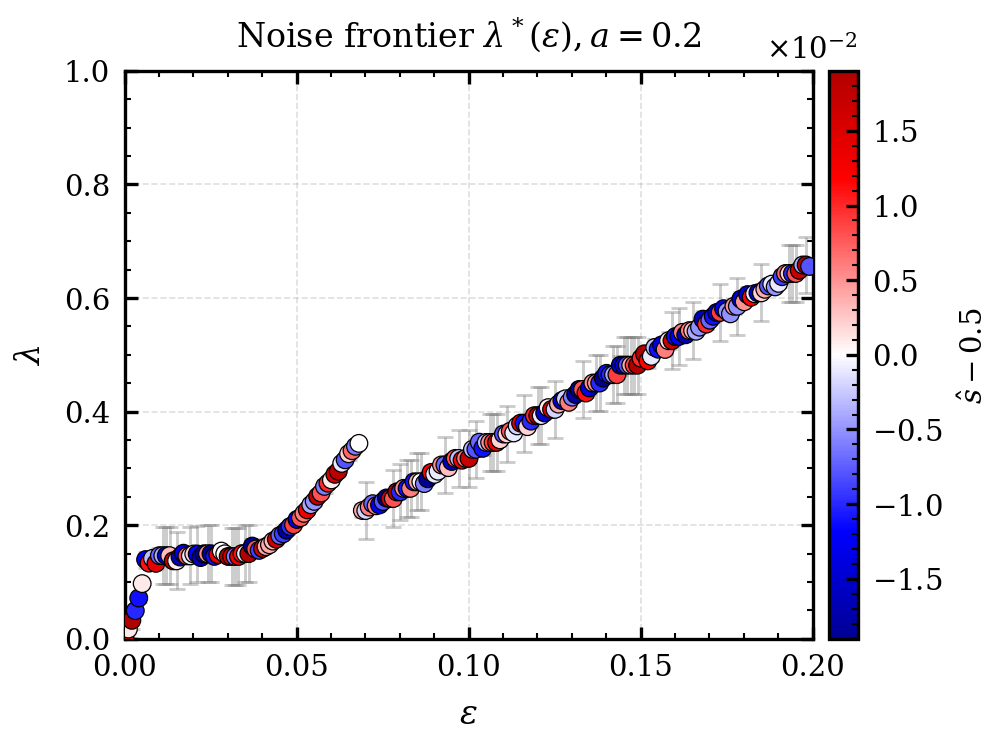

In [26]:
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.ticker as ticker
import matplotlib.colors as mcolors
import scienceplots

# ── Parse .txt file ───────────────────────────────────────────────────────────
import re

def parse_iqae_ceiling_file(filepath):
    """
    Parse an IQAE ceiling-mode frontier data export file.
    Extracts the first 5 columns: epsilon, p_star, uncertainty, s_hat, n_shots
    """
    epsilons      = []
    p_stars       = []
    uncertainties = []
    s_hats        = []
    n_shots       = []

    with open(filepath, "r", encoding="utf-8", errors="replace") as f:
        lines = f.readlines()

    in_data_section = False

    for line in lines:
        line = line.strip()

        if line.startswith("epsilon | p_star"):
            in_data_section = True
            continue

        if in_data_section and set(line) <= set("-"):
            continue

        if in_data_section and "|" in line:
            parts = [p.strip() for p in line.split("|")]
            epsilons.append(float(parts[0]))
            p_stars.append(float(parts[1]))
            uncertainties.append(float(parts[2]))
            s_hats.append(float(parts[3]))
            n_shots.append(int(parts[4]))

    return (
        np.array(epsilons),
        np.array(p_stars),
        np.array(uncertainties),
        np.array(s_hats),
        np.array(n_shots),
    )


# ── Load data ─────────────────────────────────────────────────────────────────
epsilon, p_star, p_uncertainty, s_hat, n_shots = parse_iqae_ceiling_file(
    "adaptive_searchCP_Nmax, a = 0.2, k-depedent.txt"
)

# ── Filter to epsilon in [0, 0.2] ─────────────────────────────────────────────
mask        = (epsilon >= 0.0) & (epsilon <= 0.2)
epsilon     = epsilon[mask]
p_star      = p_star[mask]
p_uncertainty = p_uncertainty[mask]
s_hat       = s_hat[mask]
n_shots     = n_shots[mask]

# ── Style ─────────────────────────────────────────────────────────────────────
plt.style.use(['science', 'bright'])

COLUMN_WIDTH_IN = 3.5
ASPECT_RATIO    = 3.0 / 4.0
FONT_SIZE       = 8

plt.rcParams.update({
    'figure.figsize'      : (COLUMN_WIDTH_IN, COLUMN_WIDTH_IN * ASPECT_RATIO),
    'figure.dpi'          : 300,
    'text.usetex'         : False,
    'font.family'         : 'serif',
    'font.size'           : FONT_SIZE,
    'axes.labelsize'      : FONT_SIZE,
    'axes.titlesize'      : FONT_SIZE,
    'xtick.labelsize'     : FONT_SIZE - 1,
    'ytick.labelsize'     : FONT_SIZE - 1,
    'lines.linewidth'     : 1.2,
    'axes.linewidth'      : 0.8,
    'axes.grid'           : True,
    'grid.linewidth'      : 0.4,
    'grid.alpha'          : 0.4,
    'grid.linestyle'      : '--',
    'xtick.direction'     : 'in',
    'ytick.direction'     : 'in',
    'xtick.top'           : True,
    'ytick.right'         : True,
    'xtick.major.width'   : 0.8,
    'ytick.major.width'   : 0.8,
    'xtick.minor.visible' : True,
    'ytick.minor.visible' : True,
    'xtick.minor.width'   : 0.5,
    'ytick.minor.width'   : 0.5,
})

# ── Success-rate colour variable ──────────────────────────────────────────────
# s_hat is the per-run estimated success rate; centre it at 0.5
delta_s = s_hat - 0.5

# Symmetric colour limits from robust percentiles
p_lo = np.percentile(delta_s, 2)
p_hi = np.percentile(delta_s, 98)
clim = max(abs(p_lo), abs(p_hi))

# ── Truncated high-contrast colormap ─────────────────────────────────────────
def truncate_cmap(cmap_name, lo=0.10, hi=0.90, n=512):
    base = plt.cm.get_cmap(cmap_name, n)
    cols = base(np.linspace(lo, hi, n))
    return mcolors.LinearSegmentedColormap.from_list(
        f'{cmap_name}_trunc', cols
    )

cmap_contrast = truncate_cmap('seismic', lo=0.10, hi=0.90)

# ── Clamp error bars so they never exceed [0, 1] ─────────────────────────────
yerr = np.array([
    np.clip(p_uncertainty, 0, p_star),           # lower bar can't go below 0
    np.clip(p_uncertainty, 0, 1.0 - p_star),     # upper bar can't go above 1
])

# ── Plot ──────────────────────────────────────────────────────────────────────
fig, ax = plt.subplots()

# Error bars (drawn first, underneath scatter points)
ax.errorbar(
    epsilon, p_star,
    yerr=yerr,
    fmt='none',
    ecolor='grey',
    alpha=0.4,
    capsize=2.0,
    elinewidth=0.7,
    capthick=0.7,
    zorder=2,
)

# Scatter coloured by success rate
sc = ax.scatter(
    epsilon, p_star,
    c=delta_s,
    cmap=cmap_contrast,
    s=18,
    alpha=1.0,
    linewidths=0.3,
    edgecolors='k',
    vmin=-clim,
    vmax=+clim,
    zorder=3,
)

# ── Colorbar ──────────────────────────────────────────────────────────────────
cbar = fig.colorbar(sc, ax=ax, pad=0.02)
cbar.set_label(r'$\hat{s} - 0.5$', fontsize=FONT_SIZE - 1)
cbar.ax.tick_params(labelsize=FONT_SIZE - 1)

# ── Scientific notation on colorbar ticks ────────────────────────────────────
cbar.ax.yaxis.set_major_formatter(ticker.ScalarFormatter(useMathText=True))
cbar.ax.yaxis.get_major_formatter().set_powerlimits((-2, 2))
cbar.ax.yaxis.get_major_formatter().set_scientific(True)
cbar.ax.ticklabel_format(style='sci', axis='y', scilimits=(-2, 2))

# Zero reference line (mapped to normalised [0,1] colorbar coords)
cbar_zero = (0.0 - (-clim)) / (2 * clim)
cbar.ax.axhline(y=cbar_zero, color='black', linewidth=0.8, linestyle='--')

# ── Axes labels & formatting ──────────────────────────────────────────────────
ax.set_xlabel(r'$\varepsilon$')
ax.set_ylabel(r'$\lambda$')
ax.set_title(r'Noise frontier $\lambda^*(\varepsilon), a = 0.2$')

ax.xaxis.set_minor_locator(ticker.AutoMinorLocator())
ax.yaxis.set_minor_locator(ticker.AutoMinorLocator())

ax.set_xlim(0.0, 0.2)   # enforce x-axis range
ax.set_ylim(0.0, 1.0)

fig.tight_layout()
plt.show()